# UPI Scam & Mule Detection — training and evaluation

This notebook trains every model in the project and produces every number in `RESULTS.md`.
The logic lives in `train_and_evaluate.py`; each cell below runs one step so you can see the output.

**Steps**
1. Labelled UPI simulation (`upi_simulator.py`) — normal behaviour, 5 scam types, mule rings
2. Features from the same engine the dashboard uses (`fraud_detection_app/feature_engineering.py`)
3. Time-based split: warm-up (days 0–2) · train (2–18) · validation (18–23) · test (23–30)
4. Model comparison · 5. Ablation · 6. Recall by scam type · 7. Unseen scam types
8. NetworkX ring escalation · 9. Thresholds from cost / analyst budget · 10. Save model · 11. Explanations · 12. Demo datasets

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "fraud_detection_app"))
import pandas as pd, numpy as np
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
import train_and_evaluate as T

## 1–3. Data, features and split

In [2]:
exp = T.Experiment()          # loads data/upi_sim_train.csv.gz (or simulates it) and computes features
summary = exp.data_summary()
pd.DataFrame({k: v for k, v in summary.items() if k in ("train", "val", "test")}).T

[19:22:11] 127,134 transactions, fraud rate 1.83%


[19:22:15] features computed in 3.5s (27 µs per payment)


,rows,fraud_rows,fraud_rate,days
train,69992,1405,0.02,"[2.0, 18.0]"
val,20557,430,0.021,"[18.001, 22.999]"
test,27734,488,0.018,"[23.0, 29.998]"


In [3]:
print("Payments by type:"); print(exp.df.transaction_type.value_counts())
print("\nFraud payments by type:"); print(pd.Series(summary["fraud_type_counts"]))

Payments by type:
transaction_type
P2M            80537
P2P            44185
P2M_COLLECT     2412
Name: count, dtype: int64

Fraud payments by type:
mule_layering            1511
screen_share              233
fake_refund_call          226
qr_scam                   144
fake_merchant_collect     115
sim_swap                   94
dtype: int64


Feature groups and average value for normal vs fraud payments (training part only). Every feature varies — unlike the first model, where 9 features were always zero in training.

In [4]:
tr = exp.m["train"]
rows = []
for g, cols in T.FEATURE_GROUPS.items():
    for c in cols:
        rows.append({"group": g, "feature": c,
                     "normal_mean": exp.X.loc[tr & (exp.y == 0), c].mean(),
                     "fraud_mean": exp.X.loc[tr & (exp.y == 1), c].mean(),
                     "std": exp.X.loc[tr, c].std()})
pd.DataFrame(rows)

,group,feature,normal_mean,fraud_mean,std
0,amount_context,amount_log,6.239,9.134,1.448
1,amount_context,sender_balance_ratio,0.056,0.529,0.169
2,amount_context,sender_old_balance_log,10.763,10.138,1.290
3,amount_context,receiver_old_balance_log,12.363,8.803,1.721
4,amount_context,transaction_hour,14.368,14.539,4.559
5,amount_context,is_night,0.090,0.181,0.288
6,amount_context,is_p2m,0.658,0.053,0.478
7,amount_context,is_collect,0.018,0.053,0.135
8,behaviour_velocity,sender_txn_count_before_log,2.470,2.228,0.802
9,behaviour_velocity,txns_last_1h,0.150,0.498,0.419


## 4. Model comparison (test week)
Rules vs Isolation Forest vs Random Forest vs hybrid, plus the original October model for reference. Thresholds are chosen on the validation week only.

In [5]:
comparison = exp.compare()
comparison[["model", "pr_auc", "roc_auc", "budget_precision", "budget_recall", "cost_precision", "cost_recall", "cost_alerts_per_day"]]

[19:22:15]   1. Rules (hand-written)              PR-AUC 0.322


[19:22:16]   2a. Isolation Forest (no graph)      PR-AUC 0.091


[19:22:18]   2b. Isolation Forest (+ graph)       PR-AUC 0.400


[19:22:32]   3a. Random Forest (no graph)         PR-AUC 0.890


[19:22:45]   3b. Random Forest (+ graph)          PR-AUC 0.958


[19:22:59]   4. Hybrid (RF + graph + IF score)    PR-AUC 0.957


[19:23:03]   0. Original model (Oct 2026, PaySim IF) PR-AUC 0.011


,model,pr_auc,roc_auc,budget_precision,budget_recall,cost_precision,cost_recall,cost_alerts_per_day
0,"0. Original model (Oct 2026, PaySim IF)",0.011,0.240,0.003,0.008,0.017,0.984,3961.014
1,1. Rules (hand-written),0.322,0.931,0.472,0.453,0.118,0.844,499.396
2,2a. Isolation Forest (no graph),0.091,0.878,0.116,0.154,0.058,0.906,1090.526
3,2b. Isolation Forest (+ graph),0.400,0.926,0.412,0.422,0.070,0.906,905.628
4,3a. Random Forest (no graph),0.890,0.995,0.863,0.721,0.537,0.941,122.170
5,3b. Random Forest (+ graph),0.958,0.998,0.960,0.842,0.596,0.967,113.168
6,4. Hybrid (RF + graph + IF score),0.957,0.998,0.957,0.861,0.713,0.943,92.163


## 5. Ablation — what each feature group adds

In [6]:
exp.ablation()

[19:23:13]   ablation Amount & context only        RF PR-AUC 0.718


[19:23:30]   ablation + behaviour & velocity       RF PR-AUC 0.875


[19:23:44]   ablation + device                     RF PR-AUC 0.890


[19:23:59]   ablation + graph money-flow           RF PR-AUC 0.958


,features,n_features,model,pr_auc,budget_recall,cost_recall,cost_precision,mule_recall_budget
0,Amount & context only,8,Isolation Forest,0.062,0.080,0.918,0.054,0.098
1,Amount & context only,8,Random Forest,0.718,0.654,0.912,0.251,0.754
2,+ behaviour & velocity,18,Isolation Forest,0.083,0.137,0.941,0.056,0.151
3,+ behaviour & velocity,18,Random Forest,0.875,0.713,0.908,0.589,0.839
4,+ device,22,Isolation Forest,0.091,0.154,0.906,0.058,0.148
5,+ device,22,Random Forest,0.890,0.721,0.941,0.537,0.846
6,+ graph money-flow,31,Isolation Forest,0.400,0.422,0.906,0.070,0.600
7,+ graph money-flow,31,Random Forest,0.958,0.842,0.967,0.596,0.970


## 6. Recall by scam type (same 2% alert budget for every model)

In [7]:
exp.recall_by_type()

,model,qr_scam,fake_refund_call,screen_share,sim_swap,fake_merchant_collect,mule_layering
0,1. Rules (hand-written),0.295,0.196,0.50,0.429,0.091,0.534
1,2b. Isolation Forest (+ graph),0.068,0.022,0.02,0.857,0.000,0.600
2,3a. Random Forest (no graph),0.250,0.500,0.58,0.524,0.909,0.846
3,4. Hybrid (RF + graph + IF score),0.545,0.630,0.68,0.762,0.909,0.974


## 7. Unseen scam types
Each scam type is removed from training and validation, then the models are tested only on that type.

In [8]:
exp.unseen_scams()

[19:24:27]   unseen qr_scam                RF 0.50  Hybrid 0.57  IF 0.05


[19:24:56]   unseen fake_refund_call       RF 0.57  Hybrid 0.59  IF 0.04


[19:25:24]   unseen screen_share           RF 0.62  Hybrid 0.68  IF 0.02


[19:25:52]   unseen sim_swap               RF 0.19  Hybrid 0.24  IF 0.86


[19:26:20]   unseen fake_merchant_collect  RF 0.27  Hybrid 0.23  IF 0.00


,held_out_scam,test_rows,Rules,Isolation Forest,Random Forest,Hybrid,Hybrid (type seen in training)
0,qr_scam,44,0.295,0.045,0.500,0.568,0.545
1,fake_refund_call,46,0.196,0.043,0.565,0.587,0.630
2,screen_share,50,0.500,0.020,0.620,0.680,0.680
3,sim_swap,21,0.429,0.857,0.190,0.238,0.762
4,fake_merchant_collect,22,0.091,0.000,0.273,0.227,0.909


## 8. NetworkX ring escalation

In [9]:
rings_table = exp.ring_escalation()
print({k: v for k, v in exp.results["graph_rings"].items() if k != "table"})
rings_table

[19:26:20]   rings found 6 (6 mostly fraud), purity 0.92


{'rings_found': 6, 'rings_majority_fraud': 6, 'ring_payment_purity': 0.918918918918919, 'true_rings_active_in_test': 6, 'escalation_min_score': 0.01}


,setting,alerts,true_frauds,false_alerts,precision,recall,mule_layering_recall,cost_rupees
0,Model alerts only,645,460,185,0.713,0.943,0.99,317444.15
1,+ every payment inside a detected ring,691,476,215,0.689,0.975,0.99,180054.15
2,+ ring payments that are fast pass-throughs (s...,671,475,196,0.708,0.973,0.99,179054.15


## 9. Thresholds: how the review cost changes the operating point

In [10]:
exp.cost_sensitivity()

,review_cost_rupees,threshold,alerts_per_day,precision,recall,amount_recall
0,50,0.095,137.173,0.495,0.973,0.993
1,200,0.171,92.163,0.713,0.943,0.976
2,1000,0.181,89.020,0.737,0.941,0.974
3,5000,0.311,69.015,0.913,0.904,0.955


## 10–11. Save the dashboard model and check explanations against SHAP

In [11]:
bundle = exp.save_bundle()
exp.explanation_check()

[19:26:20]   saved model bundle (alert ≥ 0.171, high ≥ 0.311)


[19:26:27]   explanations: 0.82 top-1 agreement with SHAP


{'n_alerts_checked': 150,
 'additivity_max_error': 5.551115123125783e-16,
 'shap_available': True,
 'top1_agreement': 0.82,
 'top3_overlap': 0.8355555555555556,
 'global_importance_top10': {'if_anomaly_score': 0.09,
  'amount_log': 0.083,
  'sender_balance_ratio': 0.0763,
  'receiver_old_balance_log': 0.0607,
  'minutes_since_sender_inflow_log': 0.0374,
  'receiver_txn_count_before_log': 0.0248,
  'is_p2m': 0.0248,
  'receiver_inflow_24h_log': 0.0242,
  'sender_inflow_60m_log': 0.0234,
  'receiver_unique_senders_24h': 0.0216}}

## 12. Demo datasets (new simulations with different seeds)

In [12]:
exp.evaluate_demo(exp.make_demo_datasets())

[19:26:30]   dataset_1_normal_baseline.csv: 15,530 rows, 0 fraud


[19:26:33]   dataset_2_scam_attacks.csv: 15,649 rows, 229 fraud


[19:26:36]   dataset_3_mule_rings.csv: 16,566 rows, 193 fraud


,dataset,rows_scored,warmup_rows,fraud_rows,alerts,false_alert_rate,precision,recall
0,dataset_1_normal_baseline.csv,11261,4269,0,161,0.014,0.000,NaN
1,dataset_2_scam_attacks.csv,11238,4411,229,404,0.016,0.562,0.991
2,dataset_3_mule_rings.csv,11862,4704,193,376,0.016,0.489,0.953


In [13]:
import realtime_demo
exp.results["latency"] = realtime_demo.benchmark(n=2000, quiet=True)
exp.results["latency"]

{'n': 2000,
 'p50_ms': 0.9323365002273931,
 'p95_ms': 1.2077191995558678,
 'p99_ms': 1.384782620061742,
 'alerts': 0,
 'alerts_true_fraud': 0}

## Charts and write-up

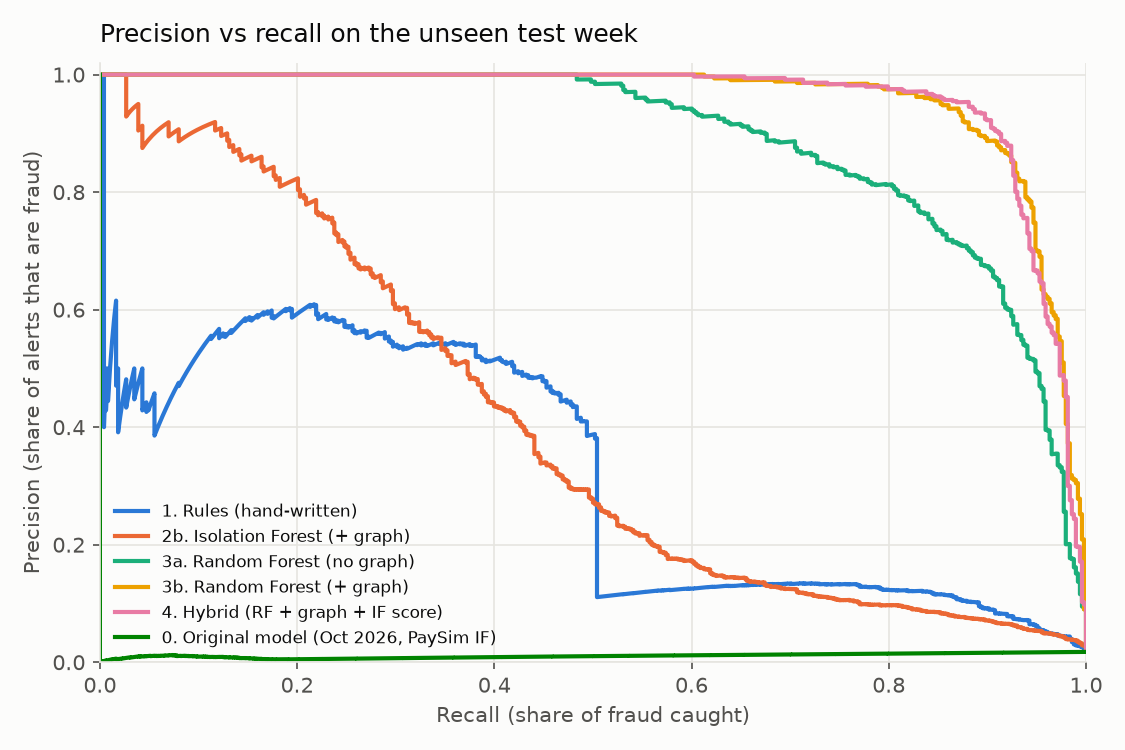

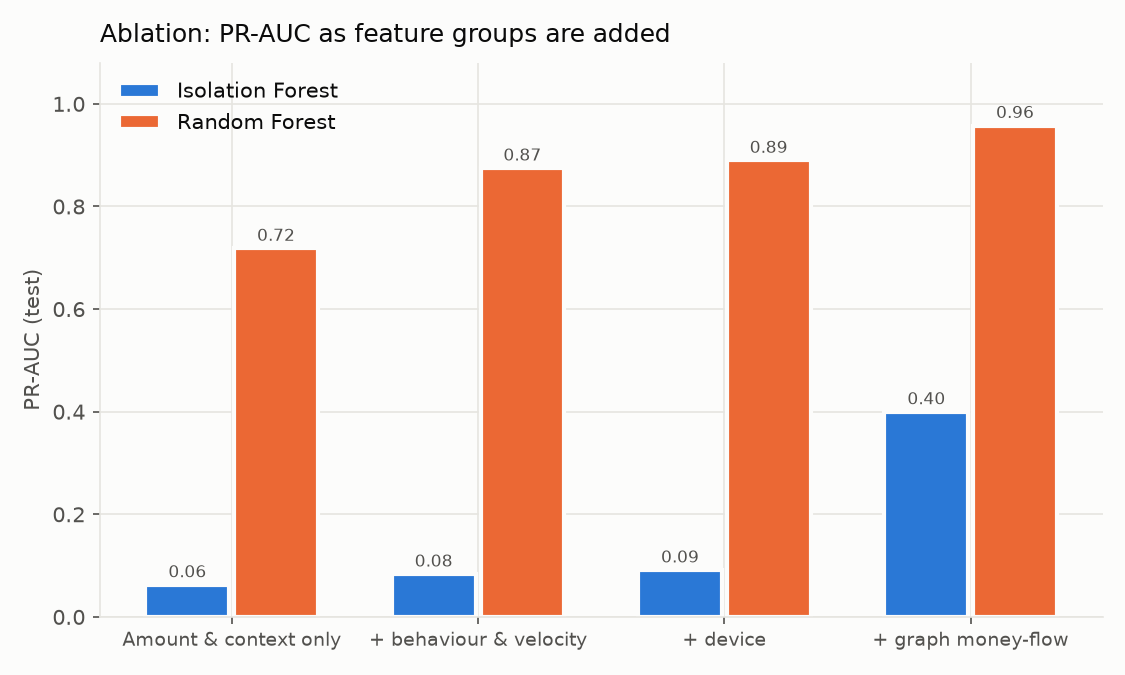

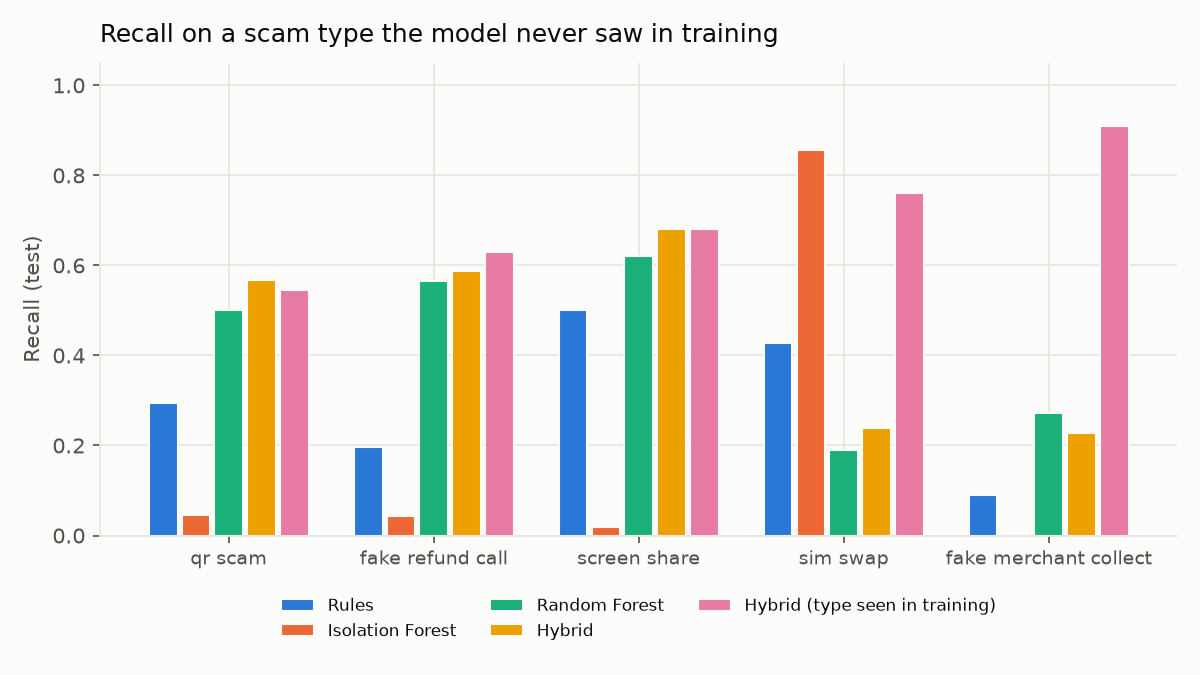

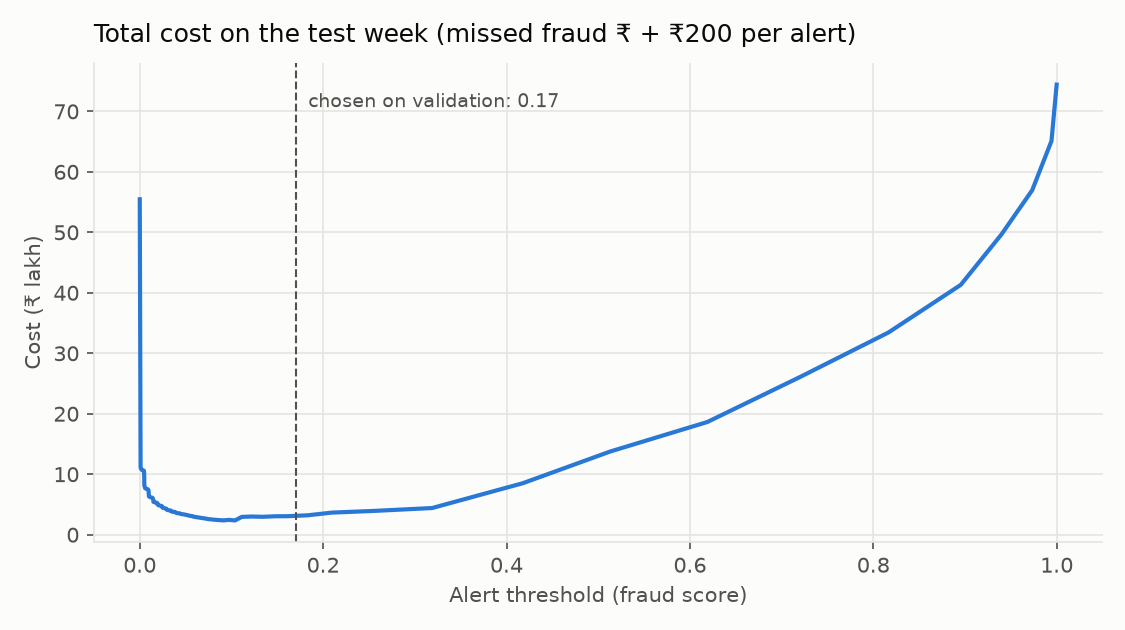

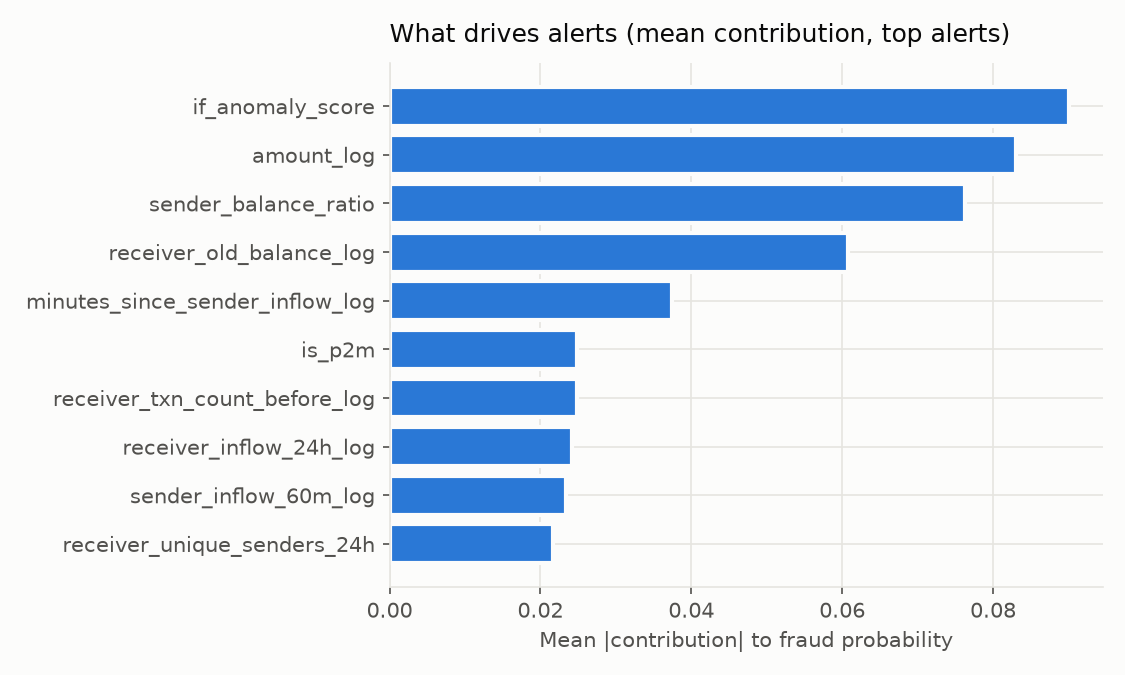

In [14]:
T.make_charts(exp); T.save_results(exp); T.write_results_md(exp)
from IPython.display import Image, display
for name in ["pr_curves", "ablation", "unseen_scams", "cost_curve", "feature_importance"]:
    display(Image(filename=str(T.RESULTS_DIR / f"{name}.png")))